# 1. Summation order — same data, different answer

**The lie.** *"Addition is associative, so the order I add things in can't
matter."*

In floating point, `(a + b) + c` and `a + (b + c)` are generally different, and
the difference grows with the *dynamic range* of the data and the number of
terms. This is not a rounding curiosity — it is why two parallel reductions of
the same array can disagree.

## The setup

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams["figure.dpi"] = 110
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

In [2]:
def naive_sum(a):
    s = 0.0
    for x in a:
        s += x
    return s

def pairwise_sum(a):
    a = np.asarray(a, dtype=float)
    if a.size <= 8:
        return float(np.sum(a))
    m = a.size // 2
    return pairwise_sum(a[:m]) + pairwise_sum(a[m:])

def kahan_sum(a):
    s = 0.0
    c = 0.0
    for x in a:
        y = x - c
        t = s + y
        c = (t - s) - y
        s = t
    return s

## The reality

In [3]:
big = 1e16
tiny = 1.0
print("naive  [1e16, 1, -1e16] =", (big + tiny) + (-big))
print("true                     =", 1.0)
print()
a = [big] + [tiny] * 100000
print("naive sum   =", naive_sum(a))
print("fsum (exact)=", __import__("math").fsum(a))

naive  [1e16, 1, -1e16] = 0.0
true                     = 1.0

naive sum   = 1e+16
fsum (exact)= 1.00000000001e+16


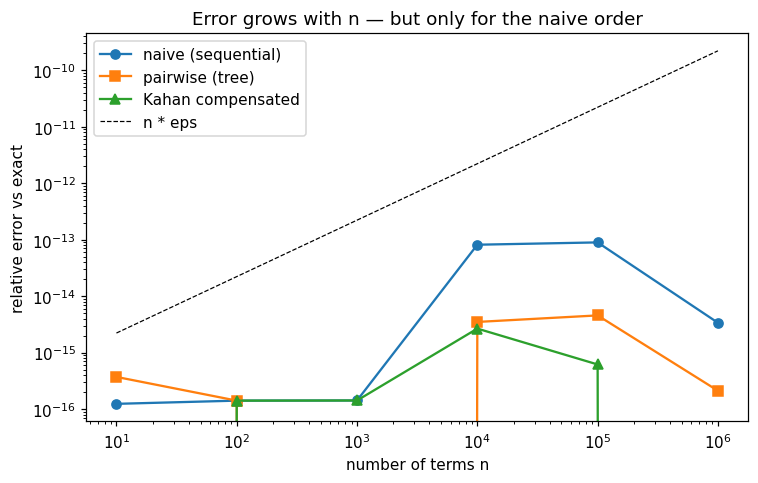

In [4]:
ns = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
naive_err, kahan_err, pw_err = [], [], []
for n in ns:
    a = rng.standard_normal(n) * 10.0 ** rng.integers(-8, 8, n)
    ref = __import__("math").fsum(a.tolist())
    naive_err.append(abs(naive_sum(a.tolist()) - ref) / max(abs(ref), 1e-300))
    kahan_err.append(abs(kahan_sum(a.tolist()) - ref) / max(abs(ref), 1e-300))
    pw_err.append(abs(pairwise_sum(a) - ref) / max(abs(ref), 1e-300))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(ns, naive_err, "o-", label="naive (sequential)")
ax.loglog(ns, pw_err, "s-", label="pairwise (tree)")
ax.loglog(ns, kahan_err, "^-", label="Kahan compensated")
ax.loglog(ns, np.array(ns) * np.finfo(float).eps, "k--", lw=0.8, label="n * eps")
ax.set_xlabel("number of terms n")
ax.set_ylabel("relative error vs exact")
ax.set_title("Error grows with n — but only for the naive order")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_sum_order.png", bbox_inches="tight")
plt.show()

## The rule

- Sequential summation accumulates error ~ `n * eps` (worst case), typically
  ~`sqrt(n) * eps` for random data. **Tree/pairwise summation** cuts it to
  ~`log2(n) * eps`.
- When it must be exact, use a compensated sum: `math.fsum` (correctly rounded),
  Kahan/Neumaier, or sort by magnitude before summing.
- In parallel code the reduction *order is not fixed*; you must choose an
  order-insensitive algorithm, not hope.

```python
math.fsum(data)                 # correctly rounded, use it by default
np.sum(data)                    # pairwise under the hood, good
data.sort(key=abs)              # then naive sum — also fine
```

## Taking it further

- Kahan (1965); Neumaier (1974) — compensated summation.
- Higham, *Accuracy and Stability of Numerical Algorithms*, ch. 4.
- `math.fsum` is exact (correctly rounded) by construction.